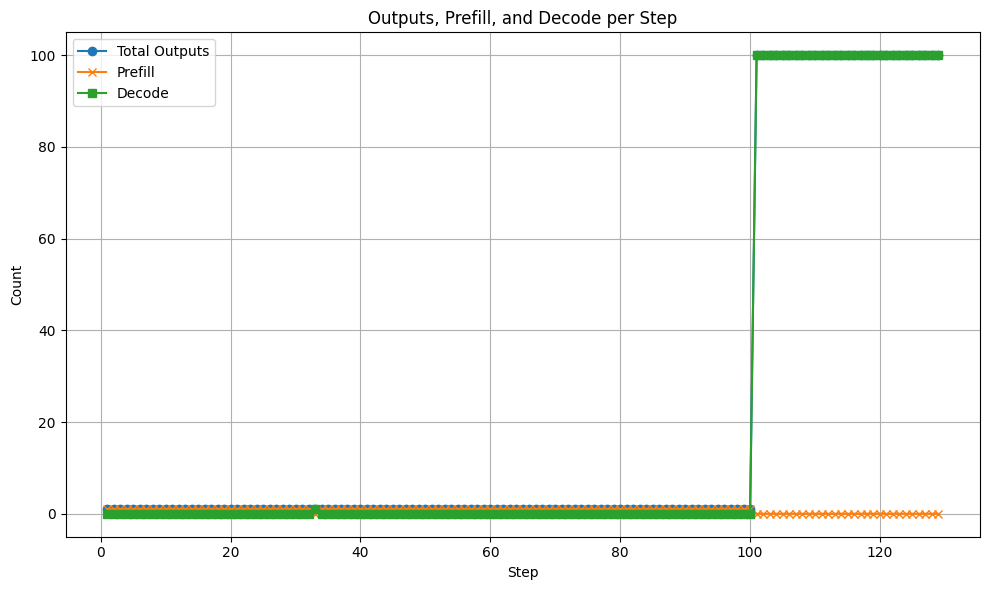

In [4]:
import re
import matplotlib.pyplot as plt

# Read file
with open("out_infinite_chunked_prefill", "r") as f:
    lines = f.readlines()

steps = []
outputs = []
prefill_counts = []
decode_counts = []

i = 0
step = 0
while i < len(lines):
    match = re.search(r"Number of outputs in this step:\s+(\d+)", lines[i])
    if match:
        k = int(match.group(1))
        step += 1
        steps.append(step)
        outputs.append(k)

        prefill, decode = 0, 0
        # Look at next k lines
        for j in range(i + 1, min(i + 1 + k, len(lines))):
            if "prefill" in lines[j].lower():
                prefill += 1
            else:
                decode += 1

        prefill_counts.append(prefill)
        decode_counts.append(decode)

        i += k  # skip past those k lines
    else:
        i += 1

# --- Plotting ---
plt.figure(figsize=(10, 6))
plt.plot(steps, outputs, marker='o', label="Total Outputs")
plt.plot(steps, prefill_counts, marker='x', label="Prefill")
plt.plot(steps, decode_counts, marker='s', label="Decode")
plt.xlabel("Step")
plt.ylabel("Count")
plt.title("Outputs, Prefill, and Decode per Step")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("../../results/vllm_batch_outputs.png")
plt.show()


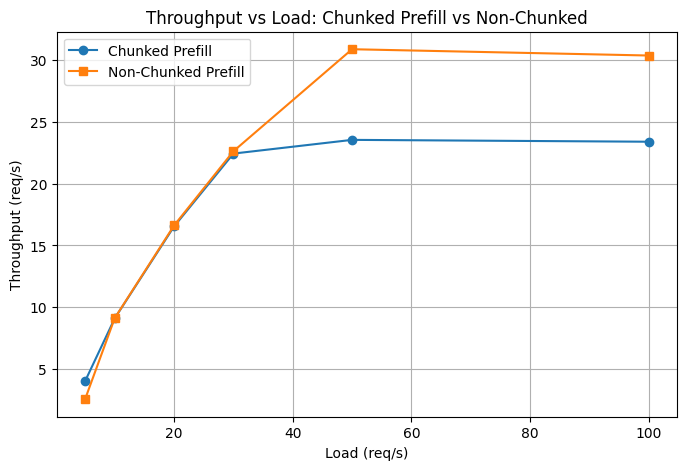

In [1]:
import matplotlib.pyplot as plt

# Data from your logs
intervals = [5, 10, 20, 30, 50, 100]

throughput_chunked = [4.01, 9.10, 16.54, 22.44, 23.55, 23.40]
throughput_nonchunked = [2.55, 9.12, 16.62, 22.63, 30.89, 30.38]

# Plot
plt.figure(figsize=(8, 5))
plt.plot(intervals, throughput_chunked, marker='o', label="Chunked Prefill")
plt.plot(intervals, throughput_nonchunked, marker='s', label="Non-Chunked Prefill")

plt.xlabel("Load (req/s)")
plt.ylabel("Throughput (req/s)")
plt.title("Throughput vs Load: Chunked Prefill vs Non-Chunked")
plt.legend()
plt.grid(True)

# Optional: reverse x-axis since smaller interval = higher RPS
# plt.gca().invert_xaxis()
plt.savefig("../../results/throughput_comparison_vllm.png")
plt.show()


Processed prompts: 90it [00:21,  4.13it/s]
Throughput:  4.125811224492807 req/s (enabling chunked prefill: True ) Interval: 0.2  Len outputs: 90
Processed prompts: 100it [00:10,  9.12it/s]
Throughput:  9.116145512261447 req/s (enabling chunked prefill: True ) Interval: 0.1  Len outputs: 100
Processed prompts: 100it [00:06, 16.66it/s]
Throughput:  16.647888542645315 req/s (enabling chunked prefill: True ) Interval: 0.05  Len outputs: 100
Processed prompts: 100it [00:04, 22.53it/s]
Throughput:  22.511542501572446 req/s (enabling chunked prefill: True ) Interval: 0.03333333333333333  Len outputs: 100
Processed prompts: 99it [00:03, 27.69it/s]
Throughput:  27.67214372429745 req/s (enabling chunked prefill: True ) Interval: 0.02  Len outputs: 99
Processed prompts: 100it [00:03, 26.93it/s]
Throughput:  26.905677481913756 req/s (enabling chunked prefill: True ) Interval: 0.01  Len outputs: 100